# Init:

In [2]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [2]:
from knowledge_maze.create_dataset.load_datasets import *

# Load all the input datasets, insert destanation path if saving is required.
tqa_dataset = load_tqa(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_nq(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_sqd(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

total_pairs = len(tqa_dataset) + len(nq_dataset) + len(sqd_dataset)
print(f'Loaded {total_pairs} question-answer pairs in total.')

ModuleNotFoundError: No module named 'ijson'

In [2]:
# Load from saved dataset:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

# 2. Classify answers:
Classify answers by types - Wikipedia entities, numbers, dates and free-form.
We will merge all the candidate datasets and discard the free-form answer, also normalize the answers for easier comparison later.

In [ ]:
from knowledge_maze.create_dataset.answer_classification import classify_dataset_answers

print('Processing TriviaQA:')
tqa_answer_types = await classify_dataset_answers(tqa_dataset, output_path=f"{REPO_PATH}\data_files\\tqa_answer_types.json")
print('Processing Natural Questions:')
nq_answer_types = await classify_dataset_answers(nq_dataset, output_path=f"{REPO_PATH}\data_files\\nq_answer_types.json")
print('Processing SQuAD:')
sqd_answer_types = await classify_dataset_answers(sqd_dataset, output_path=f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Using GPU for spaCy.
Processing TriviaQA:


Classifying Answers: 100%|███████████████████████████████████████████████████████| 78260/78260 [19:38<00:00, 66.39it/s]


Processing Natural Questions:


Extracting Entities:  24%|████████████▋                                         | 25153/106926 [09:02<28:32, 47.75it/s]

In [4]:
# Load from saved dataset:
tqa_answer_types = load_json(f"{REPO_PATH}\data_files\\tqa_answer_types.json")
nq_answer_types = load_json(f"{REPO_PATH}\data_files\\nq_answer_types.json")
sqd_answer_types = load_json(f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Merged dataset contains 225869 Q-A pairs out of original 272007(83%).


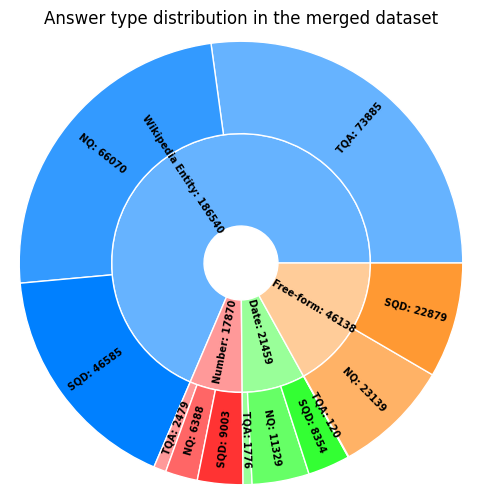

In [38]:
# Merge datasets and visualize results:
from knowledge_maze.create_dataset.answer_classification import merge_datasets

merged_dataset = merge_datasets({
                                     'TQA': tqa_answer_types,
                                     'NQ': nq_answer_types,
                                     'SQD': sqd_answer_types
                                },
                                output_path=f"{REPO_PATH}\data_files\\merged_dataset.json",
                                verbose=True)

In [49]:
# Print exapmles:
from random import choices

for sample in choices(merged_dataset, k=10):
    print(f"Question: {sample['Question']}")
    print(f"Answer: {sample['Answer']}")
    print(f"Type: {sample['Answer type']}")
    print(f"Normalized: {sample['Normalized answer']}")
    print(f"=" * 50)

Question: How many million years ago did the evolution of chimpanzees and humans diverge?
Answer: five
Type: Number
Normalized: five
Question: "What director created the popular 1980's films ""The Breakfast Club"", ""Sixteen Candles"", and ""Ferris Bueller's Day Off""?"
Answer: John Hughes
Type: Wikipedia Entity
Normalized: John Hughes
Question: where did the last name webb originate from
Answer: Northern Ireland
Type: Wikipedia Entity
Normalized: Northern Ireland
Question: May 25, 1787 saw the sitting of the Constitutional Convention. In what city did the delegates meet?
Answer: Philadelphia
Type: Wikipedia Entity
Normalized: Philadelphia
Question: During what dynasty did Nanjing become a thriving textile city?
Answer: the Song dynasty
Type: Wikipedia Entity
Normalized: Song
Question: what is the maximum number of electrons in the first energy shell of an atom
Answer: two electrons
Type: Number
Normalized: two electrons
Question: once upon a time in mumbaai based on whose story
Answer

In [3]:
# Load from saved dataset:
merged_dataset = load_json(f"{REPO_PATH}\data_files\\merged_dataset.json")

# 3. Group questions:

In [4]:
import matplotlib.pyplot as plt
%matplotlib inline
from tqdm import tqdm
from knowledge_maze.create_dataset.group_questions import generate_embeddings, cluster_wiki_entities

In [5]:
# Divide by answer type:
ent_data = []
num_data = []
date_data = []
for sample in merged_dataset:
    if sample['Answer type'] == 'Wikipedia Entity':
        ent_data.append(sample)
    elif sample['Answer type'] == 'Number':
        num_data.append(sample)
    else:
        date_data.append(sample)

In [6]:
# Cluster question by answer:
ent_clusters = cluster_wiki_entities(ent_data)
num_clusters = cluster_wiki_entities(num_data)
date_clusters = cluster_wiki_entities(date_data)
print(f'Total candidate clusters:')
print(f'Entities: {len(ent_clusters)}')
print(f'Numerical: {len(num_clusters)}')
print(f'Date & Time: {len(date_clusters)}')

Clustering Entity Questions: 100%|██████████████████████████████████████████| 21459/21459 [00:00<00:00, 2474379.92it/s]

Total candidate clusters:
Entities: 26766
Numerical: 1316
Date & Time: 1183


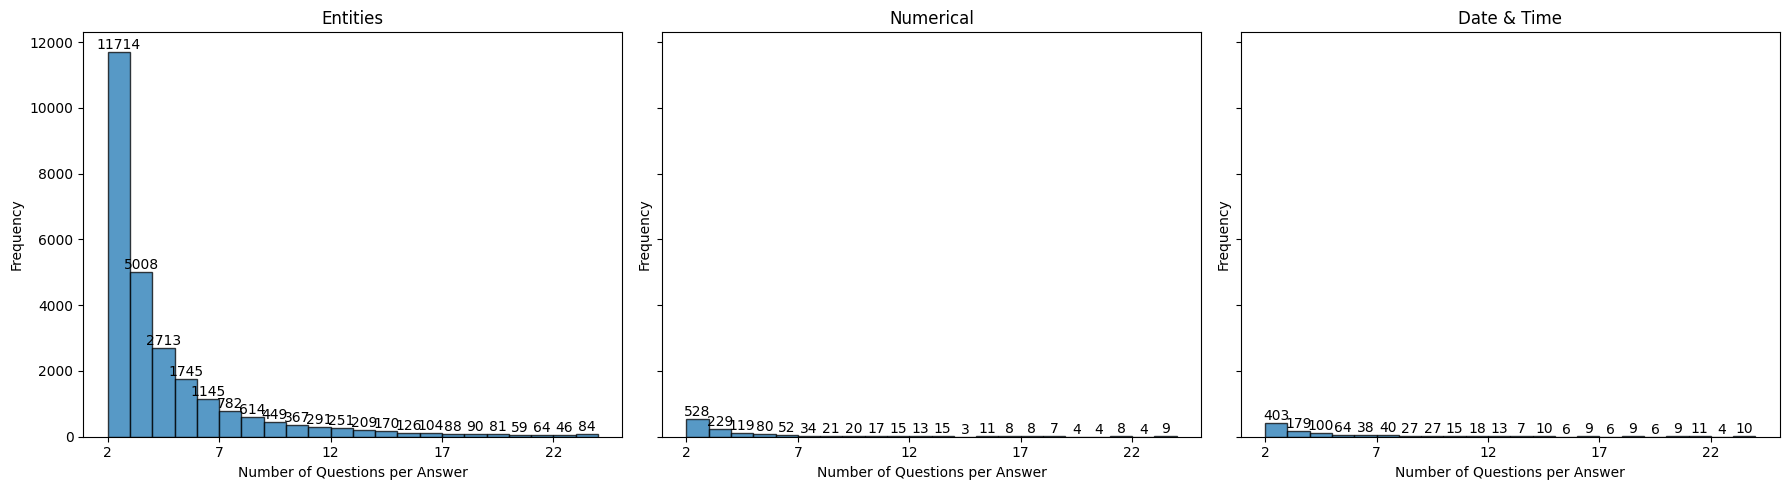

In [7]:
from knowledge_maze.create_dataset.group_questions import plot_answer_distributions
plot_answer_distributions({'Entities': ent_clusters, 'Numerical': num_clusters, 'Date & Time': date_clusters})

## 3.1 - Cluster and filter entity questions:

In [7]:
from knowledge_maze.create_dataset.group_questions import generate_question_embeddings
# Generate embeddings for all entity questions:
entity_questions_embeddings = generate_question_embeddings(ent_clusters, batch_size=256)

100%|████████████████████████████████████████████████████████████████████████████████| 542/542 [44:12<00:00,  4.89s/it]


Answer: Seekers
Questions before filtring:
1. Who sang the theme song to the 1966 film 'Georgy Girl'?
2. Which was the first Australian group to top any UK chart?
3. In 1965 who became the first Australian group to top the UK singles charts?


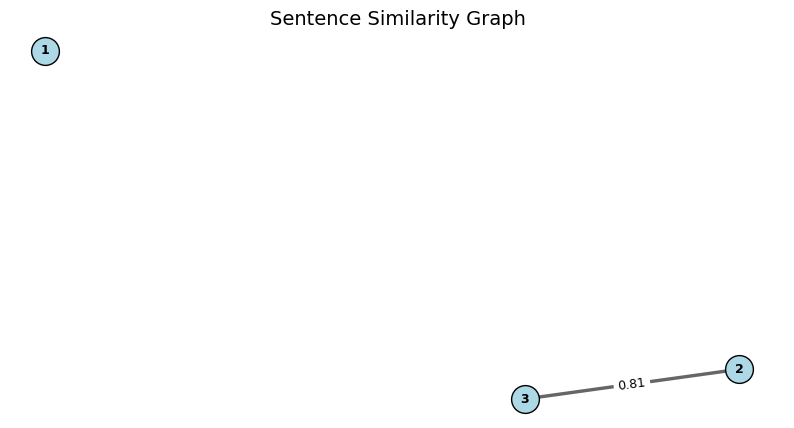

Questions after filtring:
1. Who sang the theme song to the 1966 film 'Georgy Girl'?
2. In 1965 who became the first Australian group to top the UK singles charts?


In [113]:
from random import choice
from knowledge_maze.create_dataset.group_questions import generate_sentence_similarity_graph, plot_sentence_graph, remaining_nodes_after_vertex_cover

rand_sample = choice(list(ent_clusters.items()))
print('=' * 100)
print(f'Answer: {rand_sample[0]}')
print('=' * 100)
print('Questions before filtring:')
for i, sentence in enumerate(rand_sample[1]):
    print(f'{i+1}. {sentence}')
graph = generate_sentence_similarity_graph(rand_sample[1], entity_questions_embeddings, threshold=0.7)
plot_sentence_graph(graph)
print('=' * 100)
filtered_questions = remaining_nodes_after_vertex_cover(graph)
print('Questions after filtring:')
for i, sentence in enumerate(filtered_questions):
    print(f'{i+1}. {sentence}')

In [33]:
from knowledge_maze.create_dataset.group_questions import filter_question_groups

filtered_ent_clusters = filter_question_groups(ent_clusters, entity_questions_embeddings)

100%|██████████████████████████████████████████████████████████████████████████| 26766/26766 [00:20<00:00, 1321.13it/s]


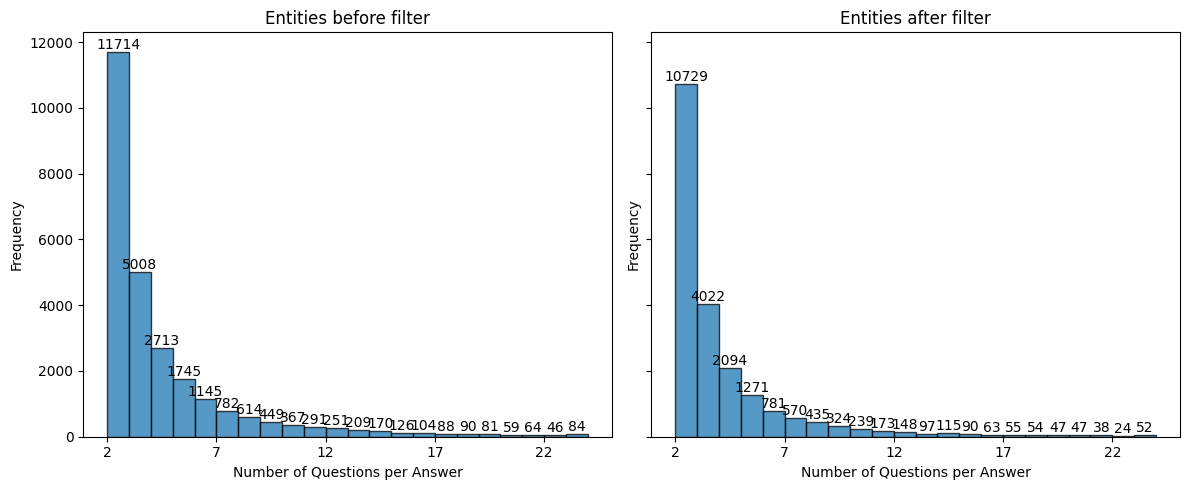

21820 out of 26766 remain after filtering (82%).


In [106]:
plot_answer_distributions({'Entities before filter': ent_clusters, 'Entities after filter': filtered_ent_clusters})
remain_clusters = {}
for answer, questions in filtered_ent_clusters.items():
    if len(questions) >= 2:
        remain_clusters[answer] = questions
print(f'{len(remain_clusters)} out of {len(ent_clusters)} remain after filtering ({round(100 * len(remain_clusters) / len(ent_clusters))}%).')

In [40]:
# Save in folder:
output_path = f"{REPO_PATH}\data_files\\filtered_cluster_ents.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(filtered_ent_clusters, out_file)

In [41]:
# Load from folder:
filtered_ent_clusters = load_json(f"{REPO_PATH}\data_files\\filtered_cluster_ents.json")

## 3.2 - Cluster and filter numerical questions:

**Structure numericals:**
1. '-' before the number.
2. hundred, thousand, million, billion ...
3. one, two, three, four ... (up to twelve)
4. spans (regex?)

In [19]:
import re

NUMBERS = {'one': 1, 'two': 2, 'three': 3, 'four': 4, 'five': 5,
           'six': 6, 'seven': 7, 'eight': 8, 'nine': 9, 'ten': 10,
           'eleven': 11, 'twelve': 12}
QUANTITIES = {'hundred': 100, 'thousand': 1_000, 'million': 1_000_000, 'billion': 1_000_000_000}
FRACTIONS = {'half': 0.5, 'quarter': 0.25, 'third': 1/3}

def extract_number(answer: str):
    """
    Extract numerical values from a string, handling words, ranges, and quantities.

    Args:
        answer (str): The input string containing numbers.

    Returns:
        int | float | str: Extracted number as int if possible, else float, or original string if no numbers exist.
    """
    # Remove commas inside numbers (e.g., "121,364" → "121364")
    answer = re.sub(r'(\d),(\d)', r'\1\2', answer)

    # Remove special characters but keep decimal points inside numbers
    answer = re.sub(r"[^\w\s.]|(?<=\d)\.(?=\D)|(?<=\D)\.(?=\d)", "", answer)

    # Handle ranges like "10-30" → take the midpoint
    range_match = re.search(r'(-?\d+\.?\d*)\s*-\s*(-?\d+\.?\d*)', answer)
    if range_match:
        num1, num2 = map(float, range_match.groups())
        midpoint = (num1 + num2) / 2
        return int(midpoint) if midpoint.is_integer() else midpoint

    # Replace number words with digits
    words = answer.lower().split()
    total = 0
    current_num = 0
    has_num = False

    for word in words:
        if word.replace('.', '', 1).isdigit():  # Check if it's a valid number (including floats)
            current_num = float(word)  # Update current number
            has_num = True
        elif word in NUMBERS:
            current_num = NUMBERS[word]  # Convert number words
            has_num = True
        elif word in QUANTITIES:
            if not has_num:
                current_num = 1  # If "million" appears alone, assume "1 million"
            current_num *= QUANTITIES[word]  # Multiply the previous number by the quantity
            total += current_num
            current_num = 0  # Reset after applying multiplier
            has_num = True
        elif word in FRACTIONS:
            fraction_value = FRACTIONS[word]
            if has_num:
                current_num += fraction_value
            else:
                current_num = fraction_value
            has_num = True
        else:
            continue

    total += current_num  # Add any remaining value

    if total > 0:
        try:
            if total.is_integer():
                return int(total)
        except:
            return total

    # Extract numeric values including decimals
    num_match = re.findall(r'[-]?\d+\.?\d*', answer)
    if num_match:
        num = float(num_match[0])
        return int(num) if num.is_integer() else num

    return answer  # If no numeric content is found, return original string

In [20]:
print(extract_number('7 million'))
print(extract_number('121,364 square miles'))
print(extract_number('1.5 million'))
print(extract_number('$5 million'))
print(extract_number('0.03 mph'))
print(extract_number('£22,590,829'))

7000000
121364
1500000
5000000
0.03
22590829


In [29]:
import numpy as np
print(np.mean([isinstance(extract_number(sample['Answer']), int) or isinstance(extract_number(sample['Answer']), float) for sample in num_data]))
print(np.mean([isinstance(extract_number(sample['Answer']), float) for sample in num_data]))
print(np.mean([isinstance(extract_number(sample['Answer']), int) for sample in num_data]))

0.9670956911024062
0.059932848349188585
0.9071628427532177


Clustering Entity Questions: 100%|██████████████████████████████████████████| 17870/17870 [00:00<00:00, 1559133.24it/s]


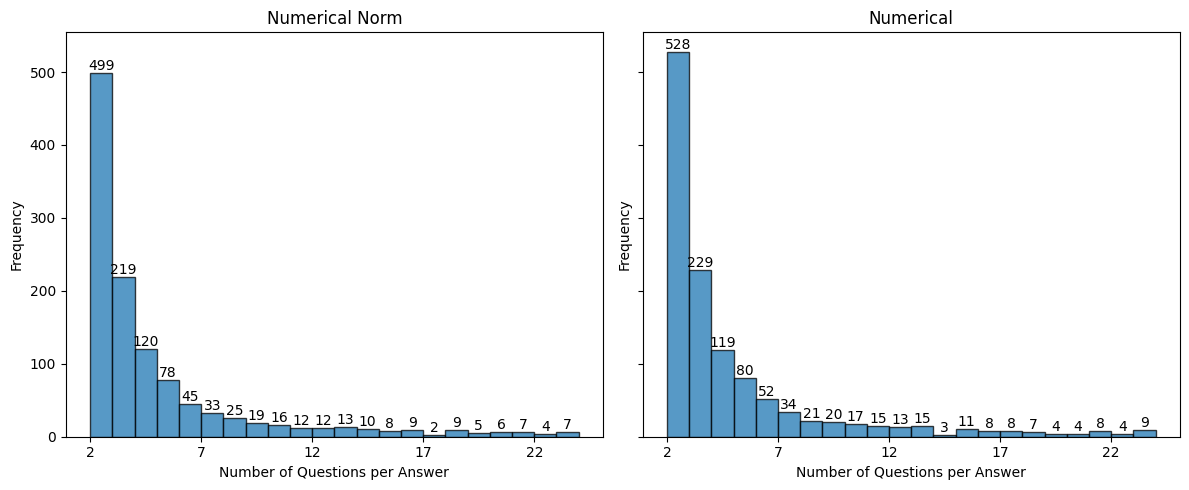

In [33]:
normalized_numericals = [extract_number(sample['Answer']) for sample in num_data]
clustered_normalized_numericals = cluster_wiki_entities([{'Question': sample['Question'], 'Normalized answer': answer} for sample, answer in zip(num_data, normalized_numericals)])

plot_answer_distributions({'Numerical Norm': clustered_normalized_numericals, 'Numerical': num_clusters})

In [60]:
BINS = [
    (0, 10), (11, 50), (51, 100), (101, 500), (501, 1000),  
    (1001, 5000), (5001, 10_000), (10_001, 50_000), (50_001, 100_000),
    (100_001, 500_000), (500_001, 1_000_000),  
    (1_000_001, 10_000_000), (10_000_001, 100_000_000), (100_000_001, 1_000_000_000), (1_000_000_001, float("inf"))
]

def assign_to_bin(number, bins):
    """Assign a number to a predefined bin."""
    for lower, upper in bins:
        if lower <= number <= upper:
            return (lower, upper)  # Return the bin range
    return None  # Should never happen if bins are well-defined

# Example usage:
cands = list(clustered_normalized_numericals)
numbers = []
for cand in cands:
    if isinstance(cand, int):
        numbers.append(cand)
binned_numbers = {num: assign_to_bin(num, BINS) for num in numbers}

for num, bin_range in binned_numbers.items():
    print(f"{num} → Bin: {bin_range}")

1 → Bin: (0, 10)
2 → Bin: (0, 10)
3 → Bin: (0, 10)
4 → Bin: (0, 10)
5 → Bin: (0, 10)
6 → Bin: (0, 10)
7 → Bin: (0, 10)
8 → Bin: (0, 10)
9 → Bin: (0, 10)
10 → Bin: (0, 10)
11 → Bin: (11, 50)
12 → Bin: (11, 50)
13 → Bin: (11, 50)
14 → Bin: (11, 50)
15 → Bin: (11, 50)
16 → Bin: (11, 50)
17 → Bin: (11, 50)
18 → Bin: (11, 50)
19 → Bin: (11, 50)
20 → Bin: (11, 50)
22 → Bin: (11, 50)
23 → Bin: (11, 50)
24 → Bin: (11, 50)
25 → Bin: (11, 50)
26 → Bin: (11, 50)
27 → Bin: (11, 50)
28 → Bin: (11, 50)
21 → Bin: (11, 50)
30 → Bin: (11, 50)
29 → Bin: (11, 50)
32 → Bin: (11, 50)
33 → Bin: (11, 50)
35 → Bin: (11, 50)
36 → Bin: (11, 50)
37 → Bin: (11, 50)
38 → Bin: (11, 50)
39 → Bin: (11, 50)
40 → Bin: (11, 50)
41 → Bin: (11, 50)
42 → Bin: (11, 50)
43 → Bin: (11, 50)
44 → Bin: (11, 50)
45 → Bin: (11, 50)
46 → Bin: (11, 50)
48 → Bin: (11, 50)
49 → Bin: (11, 50)
50 → Bin: (11, 50)
51 → Bin: (51, 100)
52 → Bin: (51, 100)
53 → Bin: (51, 100)
54 → Bin: (51, 100)
55 → Bin: (51, 100)
56 → Bin: (51, 100)
57 → B

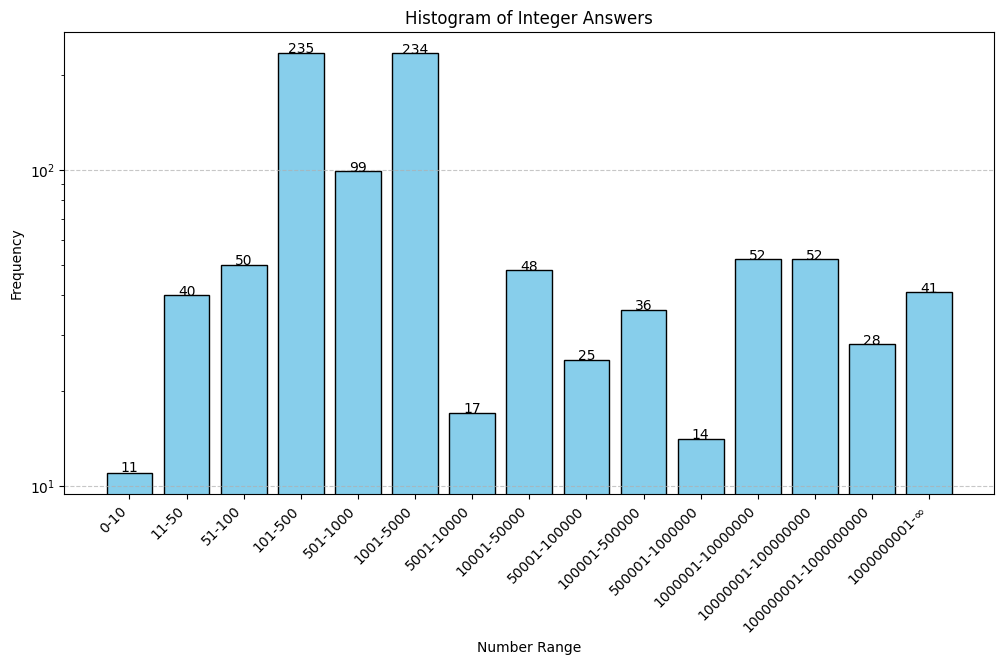

In [61]:
# Assign numbers to bins
bin_counts = {bin_range: 0 for bin_range in BINS}
for num in numbers:
    for bin_range in BINS:
        if bin_range[0] <= num <= bin_range[1]:
            bin_counts[bin_range] += 1
            break

# Prepare x-axis labels & y-values
bin_labels = [f"{low}-{high if high != float('inf') else '∞'}" for low, high in BINS]
counts = list(bin_counts.values())

# Plot histogram
plt.figure(figsize=(12, 6))
plt.bar(bin_labels, counts, color="skyblue", edgecolor="black")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Frequency")
plt.xlabel("Number Range")
plt.title("Histogram of Integer Answers")
plt.yscale("log")  # Log scale to handle large variations
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Display values on top of bars
for i, count in enumerate(counts):
    plt.text(i, count + 0.1, str(count), ha="center", fontsize=10)

plt.show()

## 3.3 - Cluster and filter date & time questions:

In [114]:
import re

MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 
          'July', 'August', 'September', 'October', 'November', 'December']
DAYS = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

# Categorized lists
day_answers = []
month_answers = []
year_answers = []
decade_answers = []
centuries_answers = []
generic_month_answers = []
generic_days_answers = []
full_date_answers = []
year_span_answers = []
rest_data = []

# Regex pattern for different year span formats, including shorthand years (e.g., "1933 -- 35")
YEAR_SPAN_PATTERN = re.compile(r'(\d{4})\s*[-–—]{1,2}\s*(\d{2,4})|(\d{4})\s+to\s+(\d{2,4})', re.IGNORECASE)

for sample in date_data:
    answer = sample['Answer']
    words = answer.split()

    # Case: Full date (day, month, year in any order)
    if any(month in words for month in MONTHS) and any(word.isdigit() and len(word) == 4 for word in words) and any(word.isdigit() and len(word) <= 2 for word in words):
        full_date_answers.append(answer)

    # Case: Year span (handles "YYYY - YYYY", "YYYY -- YYYY", "YYYY — YYYY", "YYYY to YYYY", AND "YYYY -- YY")
    elif YEAR_SPAN_PATTERN.search(answer):
        match = YEAR_SPAN_PATTERN.search(answer)
        year1 = int(match.group(1) or match.group(3))  # First year
        year2 = match.group(2) or match.group(4)  # Second year (could be short form)

        # If year2 is a two-digit year, expand it correctly
        if year2 and len(year2) == 2:
            base_year = year1 // 100 * 100  # Get the century part (e.g., 1900 for 1933)
            year2 = base_year + int(year2)  # Convert "35" → "1935"

        year_span_answers.append(f"{year1} - {year2}")

    # Case: Month + Year in any order (e.g., "March 2020" or "2020 March")
    elif len(words) == 2 and any(word in MONTHS for word in words) and any(word.isdigit() and len(word) == 4 for word in words):
        month_answers.append(answer)

    # Case: Day + Month in any order (e.g., "March 15" or "15 March")
    elif len(words) == 2 and any(word in MONTHS for word in words) and any(word.isdigit() and len(word) <= 2 for word in words):
        day_answers.append(answer)

    # Case: Single year (e.g., "1999")
    elif len(words) == 1 and words[0].isdigit() and int(words[0]) > 1000:
        year_answers.append(answer)

    # Case: Decades (e.g., "1920s")
    elif len(words) == 1 and words[0][-1] == 's' and words[0][:-1].isdigit():
        decade_answers.append(answer)

    # Case: Centuries (e.g., "18th century", "20th century")
    elif 'century' in answer:
        centuries_answers.append(answer)

    # Case: Generic Month (e.g., "July")
    elif len(words) == 1 and words[0] in MONTHS:
        generic_month_answers.append(answer)

    # Case: Generic Day (e.g., "Monday")
    elif len(words) == 1 and words[0] in DAYS:
        generic_days_answers.append(answer)

    else:
        rest_data.append(answer)

# Print results
print('days: ', len(day_answers))
print('generic days: ', len(generic_days_answers))
print('months: ', len(month_answers))
print('generic months: ', len(generic_month_answers))
print('years: ', len(year_answers))
print('decades: ', len(decade_answers))
print('centuries: ', len(centuries_answers))
print('full dates: ', len(full_date_answers))
print('year spans: ', len(year_span_answers))
print('rest: ', len(rest_data))

days:  546
generic days:  97
months:  1455
generic months:  353
years:  12169
decades:  423
centuries:  526
full dates:  1932
year spans:  506
rest:  3452


In [115]:
sorted(rest_data)

['"Class of \'67"',
 '"Fourth of June"',
 '"Late Qing Reform"',
 '"Ten-Year Housing Plan"',
 "'07",
 '( 1987 )',
 '(1992)',
 '(2000',
 '(2006)',
 '(24 June)',
 '(309239) 2007 RW10',
 '1 day',
 '1,400 years',
 '1,500 BCE',
 '1,800 years ago',
 '1.2 years',
 '1.2 years longer',
 '10 Days',
 '10 YEARS',
 '10 days',
 '10 days',
 '10 days',
 '10 days',
 '10 days',
 '10 months',
 '10 months',
 '10 months',
 '10 months',
 '10 weeks',
 '10 years',
 '10 years',
 '10 years',
 '10 years',
 '10 years',
 '10 years',
 '10 years',
 '10 years old',
 '10,000 years ago',
 '10,000 years ago',
 '10,000 years ago',
 '10,000 years ago',
 '10-year',
 '10-year',
 '10.12. 6',
 '10.13. 6',
 '10.13. 6',
 '10/11 May 1941',
 '10/13 Communications',
 '100 Years',
 '100 years',
 '100 years',
 '100 years',
 '1000 CE',
 '1046 BC',
 '105 AD',
 '1066 AD',
 '108 - year',
 '10th millennium BC',
 '10th millennium BC',
 '11 May 330',
 '11 years',
 '11,000 years ago',
 '11.5 months',
 '110 million years',
 '1100 BC',
 '114 B

In [122]:
for sample in date_data:
    if sample['Answer'] == '20 years':
        print(sample['Question'])

What is the minimum alcohol drinking age in bars in Iceland?
How long is a US patent good for (as of June 9, 1995)?
how long did it take to build great pyramid of giza
Approximately how long did it take to build New Delhi?
How long does it take for patents to expire after being filed?
How long do drug exclusivity rights usually last?
How long had Richard Gephart served in house prior to being elected to minority leader?


# 4. Create paragraphs: